# Stationarity and Ergodicity



## Stationarity


:::{#fig-ts-concept}

{{< video ./figures/ergodicity/TSConcept.mp4 >}}

:::

## Joint and Marginal Distributions, Moments



In [3]:
#| label: tab-joint-distribution
#| fig-cap: "Joint Probability Distribution of X and Y"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pxy = pd.read_csv("https://github.com/febse/data/raw/refs/heads/main/ts/review/pxy.csv")[['x', 'y', 'p']]
pxy.pivot(
    index='x',
    columns='y',
    values='p'
).add_prefix('y=')

y,y=2,y=3
x,,
0,0.241,0.009
1,0.089,0.006
2,0.229,0.043
3,0.201,0.182


The marginal distribution of $X$ is obtained by summing the joint probabilities over all values of $Y$:

$$
P(X = x) = \sum_{y} P(X = x, Y = y)
$$

Its expected value is $E(X) = \sum_x x \, P(X = x)$. The summation index $x$ is a shorthand notation meaning that we sum over all possible values that the random variable $X$ can take. The analogous notation $\sum_y$ is used for summing over all possible values of the random variable $Y$.


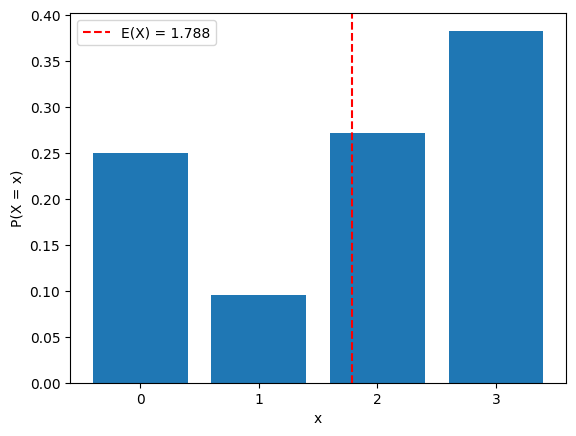

In [4]:
#| label: fig-marginal-x
#| fig-cap: "Marginal distribution of X. The dashed line shows the expected value E(X)."

px = pxy.groupby('x')['p'].sum()
expected_x = np.sum(px.index.to_numpy() * px.to_numpy())

fig, ax = plt.subplots()
ax.bar(px.index, px.values)
ax.axvline(expected_x, color='red', linestyle='--', label=f'E(X) = {expected_x:.3f}')
ax.set_xticks(px.index)
ax.set_xlabel('x')
ax.set_ylabel('P(X = x)')
ax.legend()
plt.show()

## Ergodicity: Ensemble Averages and Time Averages

:::{#fig-ergodicity-ar1-time}

{{< video ./figures/ergodicity/AR1Full.mp4 >}}

:::

:::{#fig-ergodicity-ar1-ensamble}

{{< video ./figures/ergodicity/AR1Ensemble.mp4 >}}

:::


In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters of the AR(1) process
phi = 0.7
constant = 3.0
sigma = 1.0

# Theoretical (ensemble) mean and variance
mean_theory = constant / (1 - phi)
variance_theory = sigma**2 / (1 - phi**2)

print(f"Theoretical mean:     {mean_theory:.2f}")
print(f"Theoretical variance: {variance_theory:.2f}")

Theoretical mean:     10.00
Theoretical variance: 1.96


We simulate $N = 2000$ independent paths, each of length $T = 1000$. The result is a matrix with one row per path and one column per time period.
Each path starts with a draw from the stationary distribution $N(\mu, \gamma_0)$, so that the process is stationary from the first period.

In [6]:
def simulate_ar1(n_paths, n_periods, rng):
    # Simulate independent AR(1) paths. Rows are paths, columns are time periods.
    paths = np.zeros((n_paths, n_periods))

    # Start every path with a draw from the stationary distribution
    paths[:, 0] = rng.normal(mean_theory, np.sqrt(variance_theory), size=n_paths)

    for t in range(1, n_periods):
        shocks = rng.normal(0, sigma, size=n_paths)
        paths[:, t] = constant + phi * paths[:, t - 1] + shocks

    return paths


rng = np.random.default_rng(2026)

n_paths = 2000
n_periods = 1000

ar1_paths = simulate_ar1(n_paths, n_periods, rng)
ar1_paths.shape

(2000, 1000)

### Ensemble average

For the ensemble average we fix a time period (a column of the matrix) and average over all paths (rows).

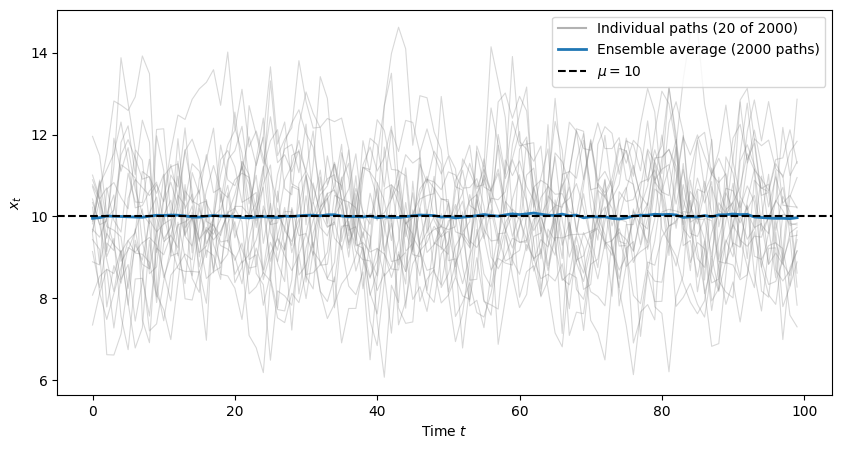

In [7]:
#| label: fig-ar1-ensemble
#| fig-cap: "AR(1): a few individual paths and the ensemble average over 2000 paths"

# Average over the paths (axis 0) for every time period
ar1_ensemble_average = ar1_paths.mean(axis=0)

periods_shown = 100

plt.figure(figsize=(10, 5))
plt.plot(ar1_paths[:20, :periods_shown].T, color="gray", alpha=0.3, linewidth=0.8)
plt.plot([], [], color="gray", alpha=0.6, label="Individual paths (20 of 2000)")
plt.plot(ar1_ensemble_average[:periods_shown], color="tab:blue", linewidth=2,
         label="Ensemble average (2000 paths)")
plt.axhline(mean_theory, color="black", linestyle="--", label=r"$\mu = 10$")
plt.xlabel("Time $t$")
plt.ylabel("$x_t$")
plt.legend()
plt.show()

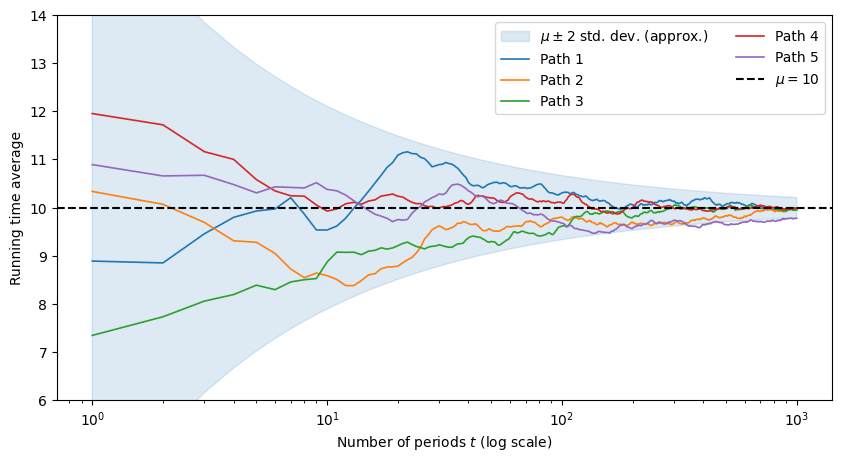

In [8]:
#| label: fig-ar1-time-average
#| fig-cap: "AR(1): running time averages of five individual paths"

time_index = np.arange(1, n_periods + 1)

# Running time average of every path: cumulative sum divided by the number of periods
ar1_running_time_average = ar1_paths.cumsum(axis=1) / time_index

# Approximate standard deviation of the time average (large t)
time_average_std = sigma / ((1 - phi) * np.sqrt(time_index))

plt.figure(figsize=(10, 5))
plt.fill_between(time_index,
                 mean_theory - 2 * time_average_std,
                 mean_theory + 2 * time_average_std,
                 color="tab:blue", alpha=0.15, label=r"$\mu \pm 2$ std. dev. (approx.)")
for path_number in range(5):
    plt.plot(time_index, ar1_running_time_average[path_number], linewidth=1.2,
             label=f"Path {path_number + 1}")
plt.axhline(mean_theory, color="black", linestyle="--", label=r"$\mu = 10$")
plt.xscale("log")
plt.ylim(6, 14)
plt.xlabel("Number of periods $t$ (log scale)")
plt.ylabel("Running time average")
plt.legend(ncol=2)
plt.show()

Every path starts somewhere else, but all running time averages converge to the same number, the ensemble mean $\mu = 10$.

Let us compare the numbers directly.

### One long path looks like the ensemble

The same holds for the whole distribution, not only for the mean. The left histogram shows the values of **all paths at one point in time** (a column of the matrix).
The right histogram shows the values of **one path over all periods** (a row). Both match the stationary distribution $N(\mu, \gamma_0)$.

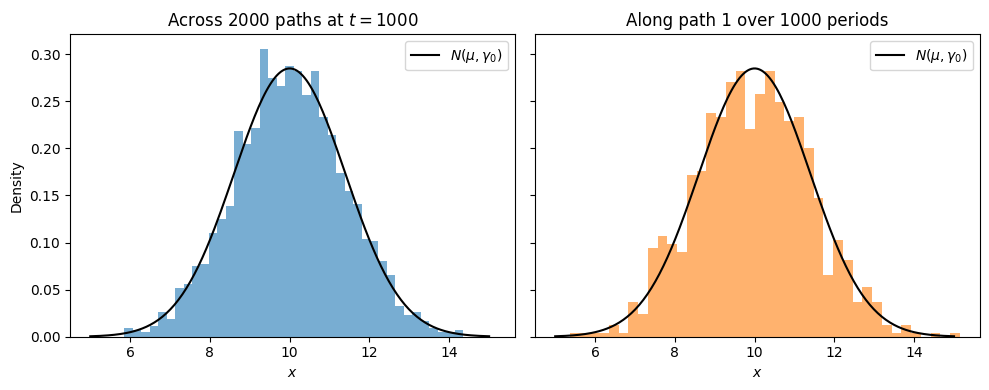

In [10]:
#| label: fig-ar1-distributions
#| fig-cap: "AR(1): distribution across paths at a fixed time and distribution over time for a single path"

grid = np.linspace(mean_theory - 5, mean_theory + 5, 200)
stationary_density = (
    np.exp(-(grid - mean_theory)**2 / (2 * variance_theory))
    / np.sqrt(2 * np.pi * variance_theory)
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

axes[0].hist(ar1_paths[:, -1], bins=40, density=True, color="tab:blue", alpha=0.6)
axes[0].set_title(f"Across {n_paths} paths at $t = {n_periods}$")

axes[1].hist(ar1_paths[0], bins=40, density=True, color="tab:orange", alpha=0.6)
axes[1].set_title(f"Along path 1 over {n_periods} periods")

for ax in axes:
    ax.plot(grid, stationary_density, color="black", label=r"$N(\mu, \gamma_0)$")
    ax.set_xlabel("$x$")
    ax.legend()

axes[0].set_ylabel("Density")
plt.tight_layout()
plt.show()

This is what makes time series analysis possible: for an ergodic process we can estimate ensemble quantities like $\mu$ from the single path that we actually observe.

All players converge to the same growth rate, but it is $-0.053$ and not the ensemble growth rate $+0.049$.
Compare this with @fig-ar1-time-average, where the time averages converged to the ensemble mean.

## Why the difference?

| | AR(1) with $\phi = 0.7$ | Multiplicative betting |
|---|---|---|
| Dynamics | additive shocks, $x_t = c + \phi x_{t-1} + e_t$ | multiplicative shocks, $W_t = W_{t-1} f_t$ |
| Effect of a shock after $k$ periods | dies out as $0.7^k$ | permanent |
| Stationary | yes | no |
| Ensemble average | $\mu = 10$ | grows like $1.05^t$ |
| Time average of a single path | converges to $\mu = 10$ | growth factor converges to $0.949 < 1$ |
| Ergodic | yes | no |

Taking logs of the betting game gives

$$
\ln W_t = \ln W_{t - 1} + \ln f_t
$$

This is an AR(1) process with coefficient $\phi = 1$: a random walk with drift $E(\ln f_t) \approx -0.053$.
The stationarity assumption $|\phi| < 1$ fails, shocks never die out, and the autocovariances are not summable.

Note that the *increments* $\ln f_t$ are independent and identically distributed and therefore ergodic.
This is exactly why the time-average growth rate of every player converges to $E(\ln f_t)$. To find out what happens to a single player over time, the right quantity to average is $\ln f_t$ and not $f_t$.

## Pure Noise: Stationary and Ergodic

The simplest stationary process is pure noise (white noise):

$$
X_t = \varepsilon_t, \qquad \varepsilon_t \overset{iid}{\sim} N(0, \sigma^2)
$$

**Assumptions:** the $\varepsilon_t$ are independent and identically distributed with mean $0$ and variance $\sigma^2$.

**Stationarity.** For every $t$ and $h$:

$$
E(X_t) = 0, \qquad \operatorname{Var}(X_t) = \sigma^2, \qquad \operatorname{Cov}(X_t, X_{t+h}) = 0 \quad (h \neq 0).
$$

The moments do not depend on $t$, and the autocovariance depends only on the lag $h$. Since the variables are i.i.d., the whole joint distribution is shift invariant.

**Ergodicity.** The autocovariances are zero for $h \neq 0$, so in particular they are summable. By the law of large numbers the time average of a single path converges to the ensemble mean:

$$
\frac{1}{T}\sum_{t=1}^{T} X_t \;\longrightarrow\; E(X_t) = 0 \quad (T \to \infty).
$$

In [ ]:
white_noise_sigma = 2.0

rng_white_noise = np.random.default_rng(2026)

n_paths_white_noise = 2000
n_periods_white_noise = 1000

# Rows are paths, columns are time periods
white_noise_paths = rng_white_noise.normal(
    0, white_noise_sigma, size=(n_paths_white_noise, n_periods_white_noise)
)

white_noise_paths.shape

### Ensemble average

We fix a period (a column) and average over the paths (rows). The ensemble mean is close to $0$ and the variance close to $\sigma^2 = 4$ in every period, which is what stationarity requires.

In [ ]:
print(f"Ensemble mean at t = 1:       {white_noise_paths[:, 0].mean():.2f}")
print(f"Ensemble mean at t = 500:      {white_noise_paths[:, 499].mean():.2f}")
print(f"Ensemble variance at t = 1:    {white_noise_paths[:, 0].var():.2f}  (theory: {white_noise_sigma**2:.2f})")
print(f"Ensemble variance at t = 500:  {white_noise_paths[:, 499].var():.2f}  (theory: {white_noise_sigma**2:.2f})")

### Time averages

Now we average over time along single paths. All of them converge to the ensemble mean $0$, and the shaded band shows $\pm 2$ standard deviations of the time average, $2\sigma/\sqrt{t}$.

In [ ]:
#| label: fig-white-noise-time-average
#| fig-cap: "White noise: running time averages of five individual paths. All converge to the ensemble mean 0."

time_index_white_noise = np.arange(1, n_periods_white_noise + 1)
white_noise_running_average = white_noise_paths.cumsum(axis=1) / time_index_white_noise

time_average_band = 2 * white_noise_sigma / np.sqrt(time_index_white_noise)

plt.figure(figsize=(10, 5))
plt.fill_between(time_index_white_noise, -time_average_band, time_average_band,
                 color="tab:blue", alpha=0.15, label=r"$\pm 2\sigma/\sqrt{t}$")
for path_number in range(5):
    plt.plot(time_index_white_noise, white_noise_running_average[path_number],
             linewidth=1.2, label=f"Path {path_number + 1}")
plt.axhline(0, color="black", linestyle="--", label=r"Ensemble mean $0$")
plt.xscale("log")
plt.xlabel("Number of periods $t$ (log scale)")
plt.ylabel("Running time average")
plt.legend(ncol=2)
plt.show()

Unlike in the random-level example below, the spread of the time averages across paths shrinks to zero.

In [ ]:
white_noise_final_average = white_noise_paths.mean(axis=1)

print(f"Variance of the time averages across paths: {white_noise_final_average.var():.4f}  (theory: sigma^2 / T = {white_noise_sigma**2 / n_periods_white_noise:.4f})")

Both averages agree: the ensemble average at a fixed time and the time average of a single path estimate the same number, $E(X_t) = 0$. Pure noise is therefore stationary **and** ergodic.

## Stationary but Not Ergodic: Random Level Plus Noise

Stationarity does not imply ergodicity. Consider the process

$$
X_t = A + \varepsilon_t, \qquad t = 1, 2, \dots
$$

**Assumptions:** $A \sim N(0, \tau^2)$ is drawn **once** at the start and then stays fixed. The noise $\varepsilon_t$ is i.i.d. $N(0, \sigma^2)$ and independent of $A$.

**Stationarity.** For every $t$ and $h$:

$$
E(X_t) = 0, \qquad \operatorname{Var}(X_t) = \tau^2 + \sigma^2, \qquad \operatorname{Cov}(X_t, X_{t+h}) = \tau^2 \quad (h \neq 0).
$$

The mean and variance do not depend on $t$, and the autocovariance depends only on the lag $h$ (in fact the whole joint distribution is shift invariant), so the process is stationary.

**No ergodicity.** The autocovariance does not decay with $h$: the random level $A$ never "wears off". Averaging over time gives

$$
\frac{1}{T}\sum_{t=1}^{T} X_t = A + \frac{1}{T}\sum_{t=1}^{T} \varepsilon_t \;\longrightarrow\; A \quad (T \to \infty),
$$

because the noise averages out but $A$ does not. The time average converges to a **random** limit $A$ and not to the ensemble mean $E(X_t) = 0$.

In [ ]:
tau = 2.0
sigma_noise = 1.0

rng = np.random.default_rng(2026)

n_paths_level = 2000
n_periods_level = 1000

# One random level per path (row), repeated over all periods, plus fresh noise in every cell
random_levels = rng.normal(0, tau, size=(n_paths_level, 1))
noise = rng.normal(0, sigma_noise, size=(n_paths_level, n_periods_level))
level_paths = random_levels + noise

level_paths.shape

### Ensemble average

As before, we fix a period (a column) and average over the paths (rows). The ensemble average is close to the true mean $0$ in every period, and the variance across paths is close to $\tau^2 + \sigma^2 = 5$.

In [ ]:
print(f"Ensemble mean at t = 1:       {level_paths[:, 0].mean():.2f}")
print(f"Ensemble mean at t = 500:      {level_paths[:, 499].mean():.2f}")
print(f"Ensemble variance at t = 500:  {level_paths[:, 499].var():.2f}  (theory: {tau**2 + sigma_noise**2:.2f})")

### Time averages

Now we average over time along single paths. Every path settles down, but each one at its own level $A$.

In [ ]:
#| label: fig-level-time-average
#| fig-cap: "Random level plus noise: running time averages of five individual paths. Each path converges to its own level A, not to the ensemble mean 0."

time_index_level = np.arange(1, n_periods_level + 1)
running_time_average = level_paths.cumsum(axis=1) / time_index_level

plt.figure(figsize=(10, 5))
for path_number in range(5):
    color = f"C{path_number}"
    plt.plot(time_index_level, running_time_average[path_number], color=color, linewidth=1.2,
             label=f"Path {path_number + 1}")
    plt.axhline(random_levels[path_number, 0], color=color, linestyle=":", linewidth=1)
plt.axhline(0, color="black", linestyle="--", label=r"Ensemble mean $0$")
plt.xscale("log")
plt.xlabel("Number of periods $t$ (log scale)")
plt.ylabel("Running time average")
plt.legend(ncol=2)
plt.show()

The dotted lines mark the random levels $A$ of the five paths. The time averages converge to them, not to the dashed line at $0$.

Across all paths, the time average at $T = 1000$ is essentially a copy of $A$ and has variance close to $\tau^2 = 4$ instead of shrinking to zero as it would for an ergodic process.

In [ ]:
final_time_average = level_paths.mean(axis=1)

print(f"Variance of the time averages across paths: {final_time_average.var():.2f}  (theory: tau^2 + sigma^2/T = {tau**2 + sigma_noise**2 / n_periods_level:.2f})")
print(f"Correlation between time average and level A: {np.corrcoef(final_time_average, random_levels[:, 0])[0, 1]:.3f}")

Compare this with the AR(1) process above: there the variance of the time average shrinks like $1/T$ and every path recovers $\mu$. Here the single path we observe tells us about its own level $A$, but nothing about the ensemble mean. Stationarity alone is therefore not enough to estimate ensemble quantities from a single realisation; we also need the dependence to die out (ergodicity).